# Step 1 — Building a target list: which stars to search, and why

Before downloading a single light curve, a transit survey has to decide **which
stars to look at**. TESS observes millions of stars in every sector; a small
project cannot (and should not) search them all. This notebook explains how to
choose a sample with a clear scientific reason behind every cut, using the
**TESS Input Catalog (TIC)**, and how to find out which of those stars TESS
actually observed in a given sector.

It needs an internet connection (it queries the MAST archive), but every query
is small: a few hundred stars at most, a few seconds each.

Where this step sits:

| step | what | input | output |
|---|---|---|---|
| **1** | **build the target list** | **TESS Input Catalog** | **one row per star (`tic_id`, magnitude, radius, mass, camera, ...)** |
| 2 | download light curves | MAST archive | one raw light-curve file per star |
| 3 | detrend | raw light curves | flattened light curves |
| 4 | transit search | flattened light curves | best periodic signal per star |
| 5 | vetting | search results | candidates |

The target list is the only input of the whole pipeline that is not a light
curve, and it carries the **stellar parameters** later steps depend on: the
search uses the star's radius and mass to decide which transit durations are
physically possible, and vetting uses the contamination ratio to judge whether
a signal could come from a neighbour.

Sections:

1. Why M dwarfs — the physics of the transit method, in numbers
2. The TESS Input Catalog: what it is and what its columns mean
3. Querying the TIC with criteria — each cut and its reason
4. Which of those stars did TESS observe in sector N? (tess-point)
5. Contamination: when the light in the aperture is not all from your star
6. The final table and the checks to run on it

In [1]:
import os
import warnings
from pathlib import Path

import dotenv
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astroquery.mast import Catalogs  # NB: `import astroquery` alone does NOT give you astroquery.mast
from tess_stars2px import tess_stars2px_function_entry

dotenv.load_dotenv(Path("..") / ".env")
SECTOR = int(os.environ.get("SECTOR", 104))
warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams["figure.figsize"] = (12, 3.5)
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 200)
print("sector:", SECTOR)

sector: 104


## 1. Why M dwarfs

M dwarfs are the smallest, coolest, most common stars: 0.1–0.6 solar radii,
2 300–4 000 K, about three quarters of the stars near the Sun. Three numbers
make them the best targets for finding small planets with a small telescope.

**1. Transit depth.** A planet of radius $R_p$ in front of a star of radius
$R_\star$ blocks a fraction of the light equal to the ratio of the disk areas:

$$\delta \approx \left(\frac{R_p}{R_\star}\right)^2 .$$

**2. Transit probability.** For a randomly oriented circular orbit of radius
$a$, the planet passes in front of the star (as seen from Earth) with
probability

$$p_{\text{transit}} \approx \frac{R_\star}{a}.$$

**3. The habitable zone is close in.** A planet receives the same light as the
Earth when $L_\star / a^2 = L_\odot / (1\,\text{AU})^2$, so
$a_{\text{HZ}} \approx \sqrt{L_\star / L_\odot}$ AU, and the luminosity of a
star scales as $L \propto R_\star^2 T_{\text{eff}}^4$. Dim stars have their
temperate zone much closer in — which means short periods (Kepler's third law,
$P^2 \propto a^3 / M_\star$), so many transits in a 27-day TESS sector.

In [2]:
R_SUN_IN_R_EARTH = 109.1
AU_IN_R_SUN = 215.0
T_SUN = 5772.0

stars = pd.DataFrame(
    {"R_star": [1.0, 0.6, 0.3, 0.15], "M_star": [1.0, 0.6, 0.3, 0.12], "Teff": [5772, 3900, 3300, 2900]},
    index=["Sun-like (G2)", "early M (M0)", "mid M (M4)", "late M (M6)"],
)
L = stars.R_star**2 * (stars.Teff / T_SUN) ** 4  # solar luminosities
a_hz = np.sqrt(L)  # AU, where the planet gets Earth's insolation
P_hz = 365.25 * np.sqrt(a_hz**3 / stars.M_star)  # days, Kepler's third law in solar units

table = pd.DataFrame(
    {
        "depth of an Earth [ppm]": (1 / (stars.R_star * R_SUN_IN_R_EARTH)) ** 2 * 1e6,
        "luminosity [L☉]": L,
        "HZ distance [AU]": a_hz,
        "HZ period [d]": P_hz,
        "transit prob. in HZ [%]": stars.R_star / (a_hz * AU_IN_R_SUN) * 100,
        "transits of a HZ planet per 27-d sector": 27 / P_hz,
    }
)
table.round(3)

,depth of an Earth [ppm],luminosity [L☉],HZ distance [AU],HZ period [d],transit prob. in HZ [%],transits of a HZ planet per 27-d sector
Sun-like (G2),84.014,1.000,1.000,365.250,0.465,0.074
early M (M0),233.372,0.075,0.274,67.601,1.019,0.399
mid M (M4),933.486,0.010,0.098,20.477,1.423,1.319
late M (M6),3733.946,0.001,0.038,7.769,1.843,3.475


Read across the table:

- An Earth-size planet gives an **84 ppm** dip on a Sun-like star — far below
  what TESS can see on a typical star in one sector — but **~1 000 ppm**
  around a mid-M dwarf and **~4 000 ppm** around a late M dwarf. Those are
  easy.
- A temperate planet around a Sun-like star transits once a year with 0.5 %
  probability. Around a mid-M dwarf, its period is a couple of weeks and the
  probability is several times higher; around a late M dwarf, it transits every
  few days.

The price: M dwarfs are **faint** (a 0.3 R☉, 3 300 K star emits ~1 % of the
Sun's light, mostly in the red and infrared). Only the **nearby** ones are
bright enough for good photometry, which is why the sample is limited by
distance (§3).

## 2. The TESS Input Catalog (TIC)

The **TIC** (version 8.2; Stassun et al. 2019, *AJ* 158, 138; arXiv:1905.10694)
is the catalogue of essentially every point source on the sky (~1.7 billion
entries), built for the TESS mission by merging Gaia DR2 with 2MASS, Tycho,
Hipparcos and other surveys. Every TESS star is identified by its **TIC ID**,
the key used in all TESS archives and catalogues of candidates. For the cool
dwarfs, radii and masses come from empirical relations calibrated on nearby M
dwarfs with measured radii (absolute K-band magnitude → radius and mass).

The TIC is served by **MAST** (the Mikulski Archive for Space Telescopes,
mast.stsci.edu). The Python way to query it is `astroquery.mast.Catalogs`:

- `Catalogs.query_object(name_or_coords, radius=deg, catalog="TIC")` — a cone
  around one object;
- `Catalogs.query_region(coordinates, radius=deg, catalog="TIC")` — same, from
  coordinates;
- `Catalogs.query_criteria(catalog="TIC", column=value, other_column=[lo, hi], ...)`
  — filter on column values over the whole sky (§3).

Let's start with one star: **LHS 3844**, an M dwarf 15 pc away with a known
transiting rocky planet. A cone of 0.05° (3 arcminutes) returns the star and
its neighbours.

In [3]:
cone = Catalogs.query_object("LHS 3844", radius=0.05, catalog="TIC").to_pandas()
print(f"{len(cone)} TIC entries within 3 arcmin;  {len(cone.columns)} columns per entry")
cols = ["ID", "dstArcSec", "Tmag", "Teff", "rad", "mass", "d", "plx", "lumclass", "objType", "contratio", "numcont"]
cone[cols].head(6)

69 TIC entries within 3 arcmin;  125 columns per entry


,ID,dstArcSec,Tmag,Teff,rad,mass,d,plx,lumclass,objType,contratio,numcont
0,410153553,0.000849,11.9238,3004.0,0.188624,0.157909,14.8846,67.154800,DWARF,STAR,0.010833,81
1,410153559,41.071166,16.6687,5006.0,1.020950,0.830000,2307.3600,0.381537,DWARF,STAR,NaN,<NA>
2,410153556,44.605812,16.7220,3659.0,0.526128,0.523276,629.3610,1.570840,DWARF,STAR,NaN,<NA>
3,410153558,50.380047,15.6977,4841.0,0.699027,0.790000,941.0610,1.035360,DWARF,STAR,NaN,<NA>
4,2054808756,52.610992,20.1405,NaN,NaN,NaN,1035.2100,3.136500,NaN,STAR,NaN,<NA>
5,2054808757,62.689035,19.9366,NaN,NaN,NaN,2237.8500,-0.744330,NaN,STAR,NaN,<NA>


The first row (0 arcsec away) is LHS 3844 itself, TIC 410153553. The columns
that matter for this project:

| column | unit | meaning |
|---|---|---|
| `ID` | — | the TIC ID |
| `ra`, `dec` | deg | sky position (epoch J2000) |
| `pmRA`, `pmDEC` | mas/yr | proper motion: how fast the star moves across the sky |
| `plx` | mas | **parallax** (from Gaia): the apparent yearly wobble of a nearby star against distant ones; distance $d\,[\text{pc}] = 1000 / \text{plx}\,[\text{mas}]$ |
| `d` | pc | distance (from the parallax) |
| `Tmag` | mag | brightness in the **TESS band** (600–1 000 nm, red/near-infrared). Magnitudes are logarithmic and *inverted*: $m = -2.5 \log_{10} F + \text{const}$, so +5 mag = 100× fainter, +1 mag ≈ 2.5× fainter |
| `Teff` | K | effective (surface) temperature |
| `rad`, `mass` | R☉, M☉ | stellar radius and mass |
| `logg`, `rho` | cgs, ρ☉ | surface gravity and mean density (derived from radius and mass) |
| `lumclass` | — | `DWARF` (main sequence) or `GIANT`/`SUBGIANT`, from the star's position in the colour–luminosity diagram |
| `objType` | — | `STAR` or `EXTENDED` (galaxies) |
| `contratio` | — | **contamination ratio**: flux from neighbours expected inside the photometric aperture, divided by the star's own flux (§5) |
| `numcont` | — | number of neighbours contributing to `contratio` |
| `GAIA` | — | Gaia DR2 source ID, for cross-matching |

Many faint stars have empty (`NaN`) `Teff`, `rad`, `mass`: no reliable colour
or distance was available. Note the neighbours here are 4–7 magnitudes fainter
than LHS 3844 (40–100× fainter), so its `contratio` is small.

## 3. Querying the TIC with criteria

`query_criteria` turns each keyword into a filter on a TIC column:

| you write | it means |
|---|---|
| `lumclass="DWARF"` | equality |
| `Teff=[2300, 4000]` | inclusive range (a two-element list) |

Column names are the TIC's own and case-sensitive (`Teff`, not `teff`). A wrong
column name comes back as an HTTP error from MAST, not a Python error.

The cuts, and the reason for each:

| cut | value | why |
|---|---|---|
| `objType` | `STAR` | drop galaxies and other extended sources |
| `lumclass` | `DWARF` | main-sequence stars only; giants are large, so planets are undetectable |
| `Teff` | 2 300 – 4 000 K | the M-dwarf range (K7/M0 boundary at ~4 000 K; below 2 300 K are brown dwarfs, and the TIC has few reliable values) |
| `rad` | ≤ 0.7 R☉ | removes stars wrongly classified as dwarfs (an "M dwarf" with $R > 0.7\,R_\odot$ is almost certainly a giant or a blend) |
| `plx` | ≥ 10 mas | distance ≤ 100 pc. Filtering on parallax instead of `d` because parallax is the measured quantity and always present when `d` is |
| `Tmag` | ≤ 14 | below that, too faint for useful photometry from full-frame images (§3.2) |

There is **no sky-position cut**: the area TESS observes in one sector is a
long strip (§4), not a circle, so it is simpler to query the whole sky once and
decide sector membership locally.

### 3.1 A small version of the query, live

The full query (d ≤ 100 pc) returns ~89 000 stars and takes 1–2 minutes. To
keep this notebook quick, run the same criteria with a 16 pc limit
(`plx ≥ 62.5 mas`): the M dwarfs in the immediate solar neighbourhood.

In [4]:
DIST_MAX_PC = 16  # the full survey uses 100 pc; 16 pc keeps the demo to a few hundred stars (and includes LHS 3844)

tab = Catalogs.query_criteria(
    catalog="TIC",
    objType="STAR",
    lumclass="DWARF",
    Teff=[2300.0, 4000.0],
    plx=[1000.0 / DIST_MAX_PC, 1e4],  # mas
    Tmag=[0.0, 14.0],
    rad=[0.0, 0.7],
)
keep = ["ID", "ra", "dec", "Tmag", "Teff", "rad", "mass", "d", "plx", "contratio", "lumclass", "objType", "GAIA", "pmRA", "pmDEC"]
near = tab[keep].to_pandas().rename(
    columns={"ID": "tic_id", "Tmag": "tmag", "Teff": "teff", "d": "dist_pc", "GAIA": "gaia_dr2_id"}
)
near["tic_id"] = near["tic_id"].astype("int64")  # some astroquery versions return the ID as a string
print(f"{len(near)} M dwarfs within {DIST_MAX_PC} pc and Tmag <= 14")
near.sort_values("dist_pc").head(10)

687 M dwarfs within 16 pc and Tmag <= 14


,tic_id,ra,dec,tmag,teff,rad,mass,dist_pc,plx,contratio,lumclass,objType,gaia_dr2_id,pmRA,pmDEC
255,325554331,269.452082,4.693364,6.88269,3259.00,0.193525,0.162651,1.82655,547.451,0.003019,DWARF,STAR,4472832130942575872,-802.803,10362.500
556,224752354,282.455683,-23.836237,7.82652,3261.00,0.210477,0.179458,2.97485,336.123,0.031500,DWARF,STAR,4075141768785646848,639.348,-193.550
651,155315739,346.466816,-35.853072,5.56640,3676.32,0.500956,0.540000,3.28679,304.219,0.001544,DWARF,STAR,6553614253923452800,6765.990,1330.390
214,325275315,176.934987,0.804557,8.24327,3163.00,0.209628,0.178601,3.37454,296.307,0.050094,DWARF,STAR,3796072592206250624,607.678,-1223.320
417,165602023,316.730267,38.742045,4.63490,3948.45,0.689846,0.610000,3.49437,286.146,1.715564,DWARF,STAR,1872046574983497216,4105.790,3155.760
0,440109718,4.607602,44.027248,8.38587,3259.00,0.195490,0.164568,3.56106,280.787,4.796906,DWARF,STAR,385334196532776576,2863.280,336.529
179,3664898,127.455637,26.776007,10.49560,2814.00,0.124013,0.099497,3.58014,279.290,0.131536,DWARF,STAR,703790044252850688,-1113.740,-612.371
390,79611981,53.998749,-44.512701,9.47068,2905.00,0.155739,0.127434,3.67278,272.245,0.000875,DWARF,STAR,4848140361962951552,745.286,-373.673
33,257870150,43.253714,16.881289,10.56500,2790.00,0.118649,0.094551,3.83078,261.015,0.000660,DWARF,STAR,35227046884571776,3429.530,-3806.160
329,200385493,77.919122,-45.018432,7.05289,3742.00,0.301994,0.278894,3.93305,254.226,0.000396,DWARF,STAR,4810594479417465600,6491.470,-5709.220


The closest is Barnard's Star (TIC 325554331, 1.8 pc). Some stars right at
the 4 000 K boundary are late-K rather than M dwarfs (e.g. 61 Cygni B,
TIC 165602023, 3.5 pc): a temperature cut is a convenient boundary, not a
sharp physical one. Distributions:

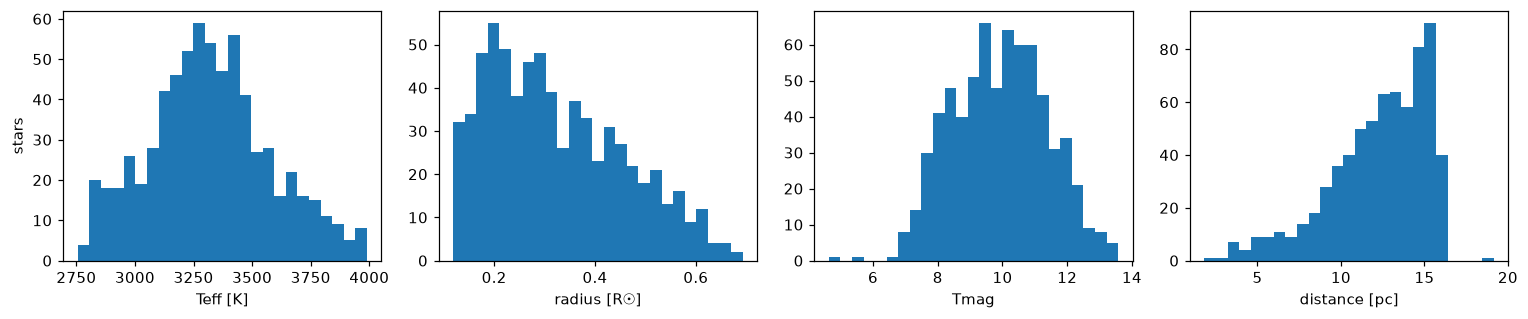

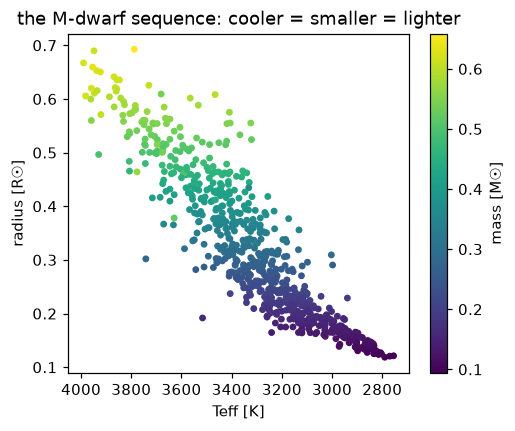

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, col, label in zip(axes, ["teff", "rad", "tmag", "dist_pc"], ["Teff [K]", "radius [R☉]", "Tmag", "distance [pc]"]):
    ax.hist(near[col].dropna(), bins=25, color="C0")
    ax.set_xlabel(label)
axes[0].set_ylabel("stars")
plt.tight_layout()

fig, ax = plt.subplots(figsize=(5, 4))
sc = ax.scatter(near["teff"], near["rad"], c=near["mass"], s=12, cmap="viridis")
ax.set_xlabel("Teff [K]"); ax.set_ylabel("radius [R☉]"); ax.invert_xaxis()
plt.colorbar(sc, label="mass [M☉]"); ax.set_title("the M-dwarf sequence: cooler = smaller = lighter");

The radius–temperature–mass relation is tight because, for main-sequence
stars, all three are set by the mass. That is also why the TIC can estimate
radius and mass for M dwarfs from just a brightness and a distance.

### 3.2 Why a magnitude limit — how much noise to expect

The precision of a light curve is limited, at best, by **photon noise**: if a
star delivers $N$ photo-electrons in an exposure, the relative uncertainty is
$1/\sqrt{N}$. TESS collects about $1.5 \times 10^4$ electrons per second from a
star of $T_\text{mag} = 10$ (Sullivan et al. 2015), and 2.5× fewer per
magnitude. Combine that with the transit depth of §1 and you can estimate the
**smallest planet** detectable at each magnitude.

A transit is detected when the dip, averaged over all in-transit points of
all transits, stands out from the noise. With $n_\text{tr}$ transits of
duration $T$, the signal-to-noise ratio is

$$
\text{SNR} \approx \frac{\delta}{\sigma_{1\text{h}}} \sqrt{n_\text{tr} \cdot T\,[\text{h}]},
$$

where $\sigma_{1\text{h}}$ is the noise of one hour of data. Requiring
SNR ≈ 7 and solving for $\delta = (R_p/R_\star)^2$ gives the minimum radius.
The real noise is higher than this photon-only estimate (sky background,
detector noise, systematics, and a floor of ~60 ppm per hour), especially for
faint stars, so treat it as the *best case*.

In [6]:
def photon_noise_ppm_per_hour(tmag):
    electrons_per_s = 1.5e4 * 10 ** (-0.4 * (tmag - 10))
    return 1e6 / np.sqrt(electrons_per_s * 3600)


def min_radius_earth(tmag, r_star, n_transits=5, duration_h=1.0, snr=7.0, floor_ppm=60.0):
    sigma_1h = np.hypot(photon_noise_ppm_per_hour(tmag), floor_ppm)
    depth = snr * sigma_1h / np.sqrt(n_transits * duration_h)
    return np.sqrt(depth * 1e-6) * r_star * R_SUN_IN_R_EARTH


tm = np.array([8, 10, 11, 12, 13, 13.5, 14, 15])
pd.DataFrame(
    {
        "photon noise, 1 h [ppm]": photon_noise_ppm_per_hour(tm),
        "min R_p, 0.5 R☉ star [R⊕]": min_radius_earth(tm, 0.5),
        "min R_p, 0.3 R☉ star [R⊕]": min_radius_earth(tm, 0.3),
        "min R_p, 0.15 R☉ star [R⊕]": min_radius_earth(tm, 0.15),
    },
    index=pd.Index(tm, name="Tmag"),
).round(2)

,"photon noise, 1 h [ppm]","min R_p, 0.5 R☉ star [R⊕]","min R_p, 0.3 R☉ star [R⊕]","min R_p, 0.15 R☉ star [R⊕]"
Tmag,,,,
8.0,54.18,0.87,0.52,0.26
10.0,136.08,1.18,0.71,0.35
11.0,215.68,1.44,0.87,0.43
12.0,341.82,1.80,1.08,0.54
13.0,541.76,2.25,1.35,0.68
13.5,682.03,2.53,1.52,0.76
14.0,858.62,2.83,1.70,0.85
15.0,1360.83,3.56,2.14,1.07


(Assumptions: 5 transits of 1 hour, SNR 7, photon noise plus a 60 ppm floor.)

Even in this optimistic estimate, at $T_\text{mag} = 14$ only planets larger
than ~1.5–3 R⊕ are within reach around a mid M dwarf; real faint-star light
curves are several times noisier. The public full-frame-image light curves
(QLP, TESS-SPOC) stop around $T_\text{mag} \approx 13.5$ for the same reason.
So **Tmag ≤ 14 is a generous limit, and tightening it to 13–13.5 loses
little**; a pipeline can start with the brightest stars and widen later.

## 4. Which of these stars did TESS observe in sector N?

### 4.1 How TESS looks at the sky

TESS has **four cameras**, each with a 24° × 24° field of view (4 CCDs per
camera), lined up into a **24° × 96° strip** — in the standard pointing, running
from the ecliptic towards the ecliptic pole (some extended-mission sectors
point elsewhere). It stares at one strip for a **sector** of ~27 days (two
orbits of the spacecraft around the Earth), then rotates by ~27° in ecliptic
longitude to the next one. After 13 sectors it has covered most of one
hemisphere. Consequences:

- Most stars are observed in **one or a few sectors** per year of observations;
  stars near the ecliptic poles (the *continuous viewing zones*) are seen
  for up to a year in a row; a band along the ecliptic was skipped in some
  years.
- Whether a star falls on a CCD in sector N is pure **geometry**: its position
  and the spacecraft pointing for that sector.

The TIC has no notion of sectors. **tess-point** (`tess_stars2px`, Burke et al.
2020) is the tool that applies the published pointing of every sector and
returns, for each star, the camera, CCD and pixel where it lands.

### 4.2 tess-point on a few stars

`tess_stars2px_function_entry(ids, ra, dec)` takes arrays (one call for any
number of stars) and returns one output row **per (star, sector) hit**:
sector, camera, CCD, column, row. Stars that never land on a CCD don't appear.
Without `trySector` it checks every sector in its pointing table — past and
planned.

In [7]:
lhs = cone.iloc[0]  # LHS 3844, from §2
demo = pd.concat([near.nsmallest(4, "dist_pc"), near[near["tic_id"] == int(lhs["ID"])]])[["tic_id", "ra", "dec"]]

out_id, _elon, _elat, out_sec, out_cam, out_ccd, out_col, out_row, _ = tess_stars2px_function_entry(
    demo["tic_id"].to_numpy(), demo["ra"].to_numpy(), demo["dec"].to_numpy()
)
hits = pd.DataFrame({"tic_id": out_id, "sector": out_sec, "camera": out_cam, "ccd": out_ccd,
                     "col_pix": out_col.round(1), "row_pix": out_row.round(1)})
hits.groupby("tic_id")["sector"].apply(lambda s: ", ".join(map(str, sorted(s.unique()))))

tic_id
155315739                           2, 28, 68, 69, 96, 106
224752354                                     92, 133, 134
325275315                                          46, 115
325554331                                     80, 118, 132
410153553    1, 27, 28, 67, 68, 94, 95, 101, 102, 103, 104
Name: sector, dtype: object

Each line is one star and every sector in which it falls (or will fall) on a
detector. LHS 3844 (TIC 410153553) is in sector 1, 27, 28, 67, 68, ... and
the sector we chose. Restricting to one sector with `trySector=N` is much
faster — that is the call to use for the full sample:

In [8]:
def stars_in_sector(df: pd.DataFrame, sector: int) -> pd.DataFrame:
    """Rows of `df` (tic_id, ra, dec, ...) that land on a TESS CCD in `sector`, with camera/ccd/pixel added."""
    out_id, _, _, out_sec, out_cam, out_ccd, out_col, out_row, _ = tess_stars2px_function_entry(
        df["tic_id"].to_numpy(), df["ra"].to_numpy(), df["dec"].to_numpy(), trySector=sector
    )
    hit = pd.DataFrame({"tic_id": out_id, "sector": out_sec, "camera": out_cam, "ccd": out_ccd,
                        "col_pix": out_col, "row_pix": out_row})
    # a star at the edge of two CCDs can be reported twice: keep one
    hit = hit[hit["sector"] == sector].drop_duplicates("tic_id")
    return df.merge(hit, on="tic_id", how="inner").reset_index(drop=True)


in_sec = stars_in_sector(near, SECTOR)
print(f"{len(in_sec)} of {len(near)} stars within {DIST_MAX_PC} pc fall on a CCD in sector {SECTOR}")
in_sec[["tic_id", "tmag", "teff", "rad", "dist_pc", "camera", "ccd", "col_pix", "row_pix"]]

36 of 687 stars within 16 pc fall on a CCD in sector 104


,tic_id,tmag,teff,rad,dist_pc,camera,ccd,col_pix,row_pix
0,201287746,9.72669,3381.0,0.327445,12.79690,3,3,1893.939814,1764.664772
1,42071226,11.10310,2973.0,0.168946,8.73900,4,4,284.840411,1990.911215
2,123366965,9.84507,3406.0,0.237209,9.36870,4,4,578.342858,113.843205
3,142206123,7.17922,3788.0,0.692694,11.53350,4,3,595.624014,1530.094146
4,231055581,9.26953,3284.0,0.287941,8.21242,4,2,1983.845178,356.565278
5,80315364,12.37460,2953.0,0.159724,14.59960,3,4,715.873939,268.786460
6,175516858,12.53080,2972.0,0.138840,14.25910,4,3,100.699624,453.986318
7,75160399,8.36522,3386.0,0.291681,5.88616,1,1,597.701342,1563.910598
8,229152539,10.91810,3155.0,0.246160,13.41370,4,2,933.798152,1359.505809
9,77111228,9.36070,3461.0,0.426039,15.19070,4,3,1679.405196,787.049058


On a map of the sky (Mollweide projection of RA/Dec), the stars of the sector
form the strip described in §4.1:

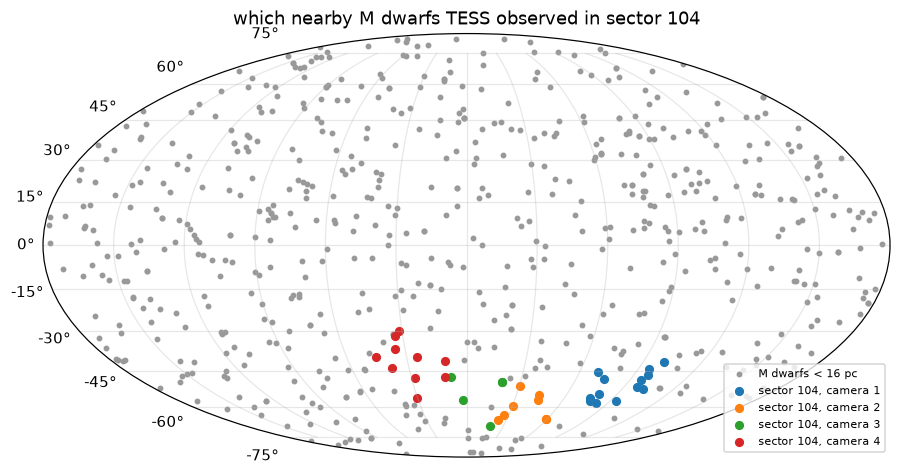

In [9]:
def to_moll(ra, dec):
    ra = np.radians(np.where(ra > 180, ra - 360, ra))
    return -ra, np.radians(dec)  # RA increases to the left on sky maps


fig = plt.figure(figsize=(10, 5))
ax = fig.add_subplot(111, projection="mollweide")
ax.scatter(*to_moll(near["ra"].values, near["dec"].values), s=8, color="0.6", label=f"M dwarfs < {DIST_MAX_PC} pc")
for cam in sorted(in_sec["camera"].unique()):
    s = in_sec[in_sec["camera"] == cam]
    ax.scatter(*to_moll(s["ra"].values, s["dec"].values), s=25, label=f"sector {SECTOR}, camera {cam}")
ax.set_xticklabels([]); ax.grid(alpha=0.3); ax.legend(loc="lower right", fontsize=7)
ax.set_title(f"which nearby M dwarfs TESS observed in sector {SECTOR}");

With the full 100 pc sample (~89 000 stars all-sky) the same code gives a
few thousand stars per sector, roughly a thousand per camera.

### 4.3 "On the detector" ≠ "has a light curve"

tess-point answers a geometric question. A light curve exists only if some
pipeline extracted one: the 2-minute **SPOC** light curves exist only for
pre-selected targets, and the full-frame-image pipelines (**QLP**,
**TESS-SPOC**) only down to a magnitude limit. Stars that land right at the
edge of a CCD (pixel column or row near 0 or ~2 048; tess-point reports the
position) usually have no light curve at all. The download
step finds out (and records `not_found` for those stars); for a spot check,
ask the archive directly for one star — this is the same query the download
step uses:

In [10]:
import lightkurve as lk

sr = lk.search_lightcurve(f"TIC {int(lhs['ID'])}", sector=SECTOR)
sr

#,mission,year,author,exptime,target_name,distance
,,,,s,,arcsec
0,TESS Sector 104,2026,SPOC,20,410153553,0.0
1,TESS Sector 104,2026,SPOC,120,410153553,0.0
2,TESS Sector 104,2026,QLP,200,410153553,0.0


## 5. Contamination: when not all the light is from your star

TESS pixels are big: **21 arcseconds** on a side, and a photometric aperture
is a few pixels across. Any star within ~1 arcminute can put some of its light
into the aperture. The TIC precomputes, for every star, the **contamination
ratio**

$$
\texttt{contratio} = \frac{\text{flux from neighbours in the aperture}}{\text{flux from the target}}.
$$

It matters in two ways:

1. **Dilution.** Extra constant light makes every dip shallower:
   $\delta_\text{observed} = \delta_\text{true} / (1 + \texttt{contratio})$.
   With `contratio = 1`, a 2 000 ppm transit looks like 1 000 ppm. The SPOC
   PDCSAP flux corrects for this (it subtracts the estimated contaminating
   flux); QLP's SAP flux does not.
2. **Blends.** If the dip is on a *neighbour* (e.g. an eclipsing binary
   20″ away), it shows up, diluted, in our star's light curve and looks like a
   planet. A large `contratio` makes this more likely. This is a vetting
   question, not a selection question.

count    683.000
mean       1.985
std       17.645
min        0.000
25%        0.003
50%        0.022
75%        0.154
max      343.486
Name: contratio, dtype: float64


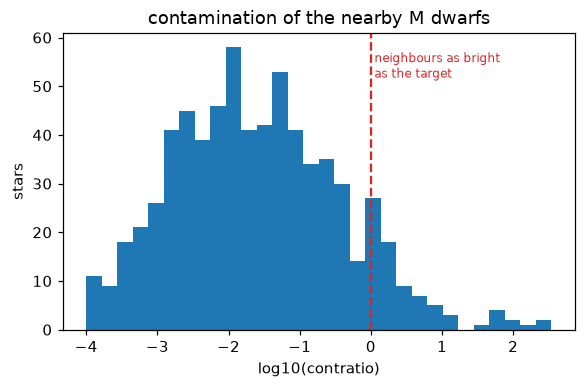

In [11]:
print(near["contratio"].describe().round(3))
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(np.log10(near["contratio"].dropna() + 1e-4), bins=30)
ax.set_xlabel("log10(contratio)"); ax.set_ylabel("stars")
ax.axvline(0, color="C3", ls="--"); ax.text(0.05, ax.get_ylim()[1] * 0.85, "neighbours as bright\nas the target", color="C3", fontsize=8)
ax.set_title("contamination of the nearby M dwarfs");

Most of these nearby stars are bright, so the median contamination is ~2 %.
But a quarter exceed 15 %, and a few exceed 1 — typically the fainter member of
a binary or a star next to a brighter neighbour. In a 100 pc sample, faint
stars in crowded fields (near the galactic plane) more often have
`contratio` > 1. We **keep** them in the target list — dropping them would
also drop genuine planets — and carry `contratio` forward for vetting.

### 5.1 One more subtlety: proper motion

TIC coordinates are for epoch 2000. Nearby M dwarfs move fast across the sky:

In [12]:
pm = np.hypot(near["pmRA"], near["pmDEC"]) / 1000  # arcsec / yr
moved = pm * 26  # arcsec moved between 2000 and 2026
print(f"median proper motion {pm.median():.2f}\"/yr; max {pm.max():.1f}\"/yr")
print(f"motion since 2000: median {moved.median():.0f}\", max {moved.max():.0f}\"  (one TESS pixel = 21\")")

median proper motion 0.58"/yr; max 10.4"/yr
motion since 2000: median 15", max 270"  (one TESS pixel = 21")


Typically less than a pixel, but more than ten pixels for the fastest
(Barnard's Star, 10″/yr). It does not change which camera or CCD
a star falls on (except right at an edge), and the TESS pipelines propagate
proper motion when they place apertures, so it does not affect the target
list. It matters later if you inspect pixel data and want to know which pixel
the star is on today.

## 6. The final table and the checks to run on it

The target list is the query result (§3), restricted to the stars on a CCD in
the chosen sector (§4), with the TIC columns renamed to something readable,
sorted by brightness (brightest first: they give the best light curves, so a
quick test on "the first N stars" uses the best data). One row per star:

| column | from | used by |
|---|---|---|
| `tic_id` | TIC `ID` | everything (the key) |
| `ra`, `dec`, `pmRA`, `pmDEC` | TIC | tess-point; later pixel-level checks |
| `tmag` | TIC `Tmag` | ordering; expected noise |
| `teff`, `rad`, `mass` | TIC | transit search (duration prior), planet radius from depth |
| `dist_pc`, `plx` | TIC | context; planet characterisation |
| `contratio` | TIC | vetting (blends, dilution) |
| `lumclass`, `objType`, `gaia_dr2_id` | TIC | bookkeeping, cross-matching |
| `sector`, `camera`, `ccd`, `col_pix`, `row_pix` | tess-point | bookkeeping; CCD-edge and per-camera checks |

In [13]:
targets = in_sec.sort_values("tmag").reset_index(drop=True)
print(targets.dtypes.to_string())
targets.head()

tic_id           int64
ra             float64
dec            float64
tmag           float64
teff           float64
rad            float64
mass           float64
dist_pc        float64
plx            float64
contratio      float64
lumclass        object
objType         object
gaia_dr2_id     object
pmRA           float64
pmDEC          float64
sector           int64
camera           int64
ccd              int64
col_pix        float64
row_pix        float64


,tic_id,ra,dec,tmag,teff,rad,mass,dist_pc,plx,contratio,lumclass,objType,gaia_dr2_id,pmRA,pmDEC,sector,camera,ccd,col_pix,row_pix
0,218263393,262.166440,-46.895193,7.15787,3451.0,0.364630,0.351090,4.54896,219.8010,0.051259,DWARF,STAR,5951824121022278144,572.5820,-880.251,104,1,4,744.734733,955.974365
1,142206123,38.594026,-43.796353,7.17922,3788.0,0.692694,0.658286,11.53350,86.6753,0.000010,DWARF,STAR,4946938113149426944,57.4758,-293.316,104,4,3,595.624014,1530.094146
2,394015919,329.894595,-59.752815,7.89256,3721.0,0.533241,0.529932,11.55440,86.5180,0.000032,DWARF,STAR,6409685433069148288,886.1090,-125.363,104,2,2,215.500059,479.163419
3,119624569,277.550026,-58.274299,8.08651,3786.0,0.579760,0.571252,14.37270,69.5475,0.043145,DWARF,STAR,6635966781495628672,-27.8908,-446.762,104,1,1,1180.886334,726.602582
4,213511261,257.746475,-52.515511,8.17551,3696.0,0.524171,0.521430,12.75740,78.3567,0.045131,DWARF,STAR,5924187617032756736,-247.5820,156.560,104,1,4,1733.106939,1434.423247


Checks worth running once on the real (100 pc) list:

1. **No missing stellar parameters** where they are needed: count `NaN` in
   `rad`, `mass`, `teff`. The transit search needs radius and mass for every
   star; decide now what to do with missing ones (a typical M-dwarf default
   such as 0.3 / 0.3, flagged).
2. **Camera balance**: roughly similar numbers per camera. A very uneven split
   suggests a wrong sector number or an outdated tess-point pointing table
   (tess-point knows sectors only up to the version you have installed).
3. **Distributions**: `teff` should pile up at 3 200–3 600 K (the most common M
   dwarfs), `tmag` should rise towards the faint limit.
4. **Known planets must be there**: pick known transiting planets around M
   dwarfs observed in that sector (the ExoFOP TOI table can be filtered by
   sector) and check their TIC IDs are in the list. If one is missing, a cut
   is wrong.
5. **Spot-check with the archive**: for a few random stars,
   `lk.search_lightcurve(f"TIC {tic}", sector=N)` returns at least one
   product (§4.3).

In [14]:
checks = {
    "stars": len(targets),
    "missing teff / rad / mass": f"{targets['teff'].isna().sum()} / {targets['rad'].isna().sum()} / {targets['mass'].isna().sum()}",
    "stars per camera": targets["camera"].value_counts().sort_index().to_dict(),
    "LHS 3844 present": 410153553 in set(targets["tic_id"]),
}
pd.Series(checks)

stars                                                36
missing teff / rad / mass                     0 / 0 / 0
stars per camera             {1: 13, 2: 8, 3: 5, 4: 10}
LHS 3844 present                                   True
dtype: object

### Summary — the recipe

1. Query the TIC all-sky once with `Catalogs.query_criteria`:
   `objType="STAR"`, `lumclass="DWARF"`, `Teff=[2300, 4000]`, `rad=[0, 0.7]`,
   `plx=[1000/d_max, 1e4]`, `Tmag=[0, 14]`. Keep ~15 columns, cast the ID to
   integer, and **cache the result** (it takes 1–2 minutes and does not depend
   on the sector).
2. Run tess-point once on all stars with `trySector=N`; keep the hits, drop
   duplicates.
3. Sort by `Tmag`, save one table per sector.
4. Run the checks above, in particular that known planets are in it.

Things that are *not* done here, on purpose: no cut on contamination (vetting
decides), no cut on whether a light curve exists (the download step finds out),
no rotation or activity cut (the detrending step deals with variable stars).

**References**: Stassun et al. 2019 (TIC v8; arXiv:1905.10694); Sullivan et al.
2015 (TESS yields and photometric precision; arXiv:1506.03845); Burke et al.
2020 (tess-point; ascl:2003.001); Winn 2010 (*Transits and Occultations*,
arXiv:1001.2010) for transit probability and depth; the MAST Catalogs API —
astroquery.readthedocs.io/en/latest/mast/mast_catalog.html.